# House Price Prediction

## 1. Project Overview

House price prediction is a supervised machine learning regression problem in which a model learns the relationship between property characteristics and their market prices. The trained model can then estimate the price of a house based on its features.

This project aims to develop and evaluate machine learning regression models using the company-provided house price dataset.

## 2. Project Objective

The main objective is to build a reliable regression model that predicts house prices using relevant property features. Multiple machine learning algorithms will be trained and compared to identify the best-performing model based on appropriate evaluation metrics.

## 3. Dataset Description

The dataset provided by the company contains information about residential properties in the United States. It includes property characteristics such as the number of bedrooms and bathrooms, living area, lot size, number of floors, waterfront status, property condition, construction year, location, and price.

The `price` column will be used as the target variable, while the relevant remaining columns will be considered as potential input features.

## 4. Project Workflow

The project will follow these stages:

1. **Data Loading:** Import the dataset into a Pandas DataFrame.
2. **Data Inspection:** Examine the dataset's structure, dimensions, data types, descriptive statistics, missing values, and duplicate records.
3. **Data Cleaning and Preprocessing:** Handle data quality issues, inspect feature types, and prepare suitable features for machine learning.
4. **Exploratory Data Analysis (EDA):** Analyze price distributions, feature relationships, correlations, and other patterns using visualizations.
5. **Feature Preparation:** Select relevant features, encode categorical variables where necessary, and split the dataset into training and testing sets.
6. **Model Training:** Train Linear Regression, Random Forest Regressor, and Gradient Boosting Regressor models.
7. **Model Evaluation:** Compare model performance using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the coefficient of determination (R²).
8. **Model Selection:** Identify the best-performing model using test-set evaluation results.
9. **Model Saving and Verification:** Save the selected model, reload it, and verify that it produces consistent predictions.

## 5. Machine Learning Algorithms

The following regression algorithms will be evaluated:

- **Linear Regression:** Establishes a baseline by modeling a linear relationship between input features and house prices.
- **Random Forest Regressor:** Combines predictions from multiple decision trees to model complex relationships.
- **Gradient Boosting Regressor:** Builds an ensemble of trees sequentially to improve predictions by learning from previous errors.

## 6. Evaluation Metrics

- **Mean Absolute Error (MAE):** Measures the average absolute difference between actual and predicted prices.
- **Root Mean Squared Error (RMSE):** Measures prediction error while penalizing larger errors more strongly.
- **R² Score:** Measures how well the model explains variation in house prices.

Lower MAE and RMSE values generally indicate better predictions, while a higher R² score generally indicates a better fit.

## 7. Expected Outcome

The expected outcome is a complete machine learning regression workflow, including data analysis, visualizations, trained models, performance comparisons, and a saved model that can predict house prices for new property records.

The final model will be selected based on its evaluation results rather than assuming that a particular algorithm will perform best.

## Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Data Loading

In this step, the company-provided house price dataset is loaded into a Pandas DataFrame. The dataset will be used for inspection, cleaning, exploratory data analysis, and regression model development.

In [2]:
df = pd.read_csv('../data/data.csv')

## 2. Initial Data Inspection

In this step, the dataset is examined to understand its dimensions, column names, data types, statistical properties, missing values, and duplicate records. These checks help identify potential data quality issues before exploratory data analysis and preprocessing.

In [3]:
df.head()

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,2014-05-02 00:00:00,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,2014-05-02 00:00:00,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,2014-05-02 00:00:00,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA


In [4]:
print("Dataset Shape:",df.shape)
print("Number of rows:",df.shape[0])
print("Number of columns:",df.shape[1])

Dataset Shape: (4600, 18)
Number of rows: 4600
Number of columns: 18


In [5]:
print('Column Names:')
print(df.columns.tolist())

Column Names:
['date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'street', 'city', 'statezip', 'country']


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           4600 non-null   str    
 1   price          4600 non-null   float64
 2   bedrooms       4600 non-null   float64
 3   bathrooms      4600 non-null   float64
 4   sqft_living    4600 non-null   int64  
 5   sqft_lot       4600 non-null   int64  
 6   floors         4600 non-null   float64
 7   waterfront     4600 non-null   int64  
 8   view           4600 non-null   int64  
 9   condition      4600 non-null   int64  
 10  sqft_above     4600 non-null   int64  
 11  sqft_basement  4600 non-null   int64  
 12  yr_built       4600 non-null   int64  
 13  yr_renovated   4600 non-null   int64  
 14  street         4600 non-null   str    
 15  city           4600 non-null   str    
 16  statezip       4600 non-null   str    
 17  country        4600 non-null   str    
dtypes: float64(4), int6

In [7]:
df.describe()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated
count,4.600000e+03,4600.000000,4600.000000,4600.000000,4.600000e+03,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000
mean,5.519630e+05,3.400870,2.160815,2139.346957,1.485252e+04,1.512065,0.007174,0.240652,3.451739,1827.265435,312.081522,1970.786304,808.608261
std,5.638347e+05,0.908848,0.783781,963.206916,3.588444e+04,0.538288,0.084404,0.778405,0.677230,862.168977,464.137228,29.731848,979.414536
min,0.000000e+00,0.000000,0.000000,370.000000,6.380000e+02,1.000000,0.000000,0.000000,1.000000,370.000000,0.000000,1900.000000,0.000000
25%,3.228750e+05,3.000000,1.750000,1460.000000,5.000750e+03,1.000000,0.000000,0.000000,3.000000,1190.000000,0.000000,1951.000000,0.000000
50%,4.609435e+05,3.000000,2.250000,1980.000000,7.683000e+03,1.500000,0.000000,0.000000,3.000000,1590.000000,0.000000,1976.000000,0.000000
75%,6.549625e+05,4.000000,2.500000,2620.000000,1.100125e+04,2.000000,0.000000,0.000000,4.000000,2300.000000,610.000000,1997.000000,1999.000000
max,2.659000e+07,9.000000,8.000000,13540.000000,1.074218e+06,3.500000,1.000000,4.000000,5.000000,9410.000000,4820.000000,2014.000000,2014.000000


In [10]:
print('Missing Values in each columns:')
print(df.isnull().sum())

Missing Values in each columns:
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
street           0
city             0
statezip         0
country          0
dtype: int64


In [11]:
print('Duplicate Rows:')
print(df.duplicated().sum())

Duplicate Rows:
0


### Data Quality Summary

The dataset contains 4,600 rows and 18 columns. It includes property characteristics, location information, construction details, and house prices.

The initial inspection found no missing values in any column and no exact duplicate rows. Therefore, no missing-value imputation or duplicate removal is required at this stage.

However, the data types, feature distributions, and unusual values still need to be examined before model training.

In [12]:
# Display data types of all columns
display(df.dtypes.rename("Data Type").to_frame())

# Statistical summary of numerical columns
display(df.describe().T)

# Check unique values in categorical columns
categorical_columns = df.select_dtypes(include="object").columns

for column in categorical_columns:
    print(f"{column}: {df[column].nunique()} unique values")

,Data Type
date,str
price,float64
bedrooms,float64
bathrooms,float64
sqft_living,int64
sqft_lot,int64
floors,float64
waterfront,int64
view,int64
condition,int64


,count,mean,std,min,25%,50%,75%,max
price,4600.0,551962.988473,563834.702547,0.0,322875.00,460943.461539,654962.50,26590000.0
bedrooms,4600.0,3.400870,0.908848,0.0,3.00,3.000000,4.00,9.0
bathrooms,4600.0,2.160815,0.783781,0.0,1.75,2.250000,2.50,8.0
sqft_living,4600.0,2139.346957,963.206916,370.0,1460.00,1980.000000,2620.00,13540.0
sqft_lot,4600.0,14852.516087,35884.436145,638.0,5000.75,7683.000000,11001.25,1074218.0
floors,4600.0,1.512065,0.538288,1.0,1.00,1.500000,2.00,3.5
waterfront,4600.0,0.007174,0.084404,0.0,0.00,0.000000,0.00,1.0
view,4600.0,0.240652,0.778405,0.0,0.00,0.000000,0.00,4.0
condition,4600.0,3.451739,0.677230,1.0,3.00,3.000000,4.00,5.0
sqft_above,4600.0,1827.265435,862.168977,370.0,1190.00,1590.000000,2300.00,9410.0


date: 70 unique values
street: 4525 unique values
city: 44 unique values
statezip: 77 unique values
country: 1 unique values


C:\Users\himan\AppData\Local\Temp\ipykernel_8908\967083267.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include="object").columns


### Data Type Preparation

The dataset contains property, date, and location features. The `date` column will be converted to a datetime format so that time-related information can be extracted if useful. The `country` column will also be checked for unique values to determine whether it provides meaningful predictive information.

The original DataFrame will be preserved, and a separate working DataFrame will be used for preprocessing.

In [13]:
# Create a working copy of the dataset
df_clean = df.copy()

# Convert date column to datetime
df_clean["date"] = pd.to_datetime(df_clean["date"], errors="coerce")

# Inspect the date conversion
print("Date data type:", df_clean["date"].dtype)
print("Invalid dates:", df_clean["date"].isna().sum())

# Inspect country values
print("\nCountry values:")
print(df_clean["country"].value_counts(dropna=False))

# Inspect the date range
print("\nDate range:")
print("Earliest:", df_clean["date"].min())
print("Latest:", df_clean["date"].max())

Date data type: datetime64[us]
Invalid dates: 0

Country values:
country
USA    4600
Name: count, dtype: int64

Date range:
Earliest: 2014-05-02 00:00:00
Latest: 2014-07-10 00:00:00


## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps identify patterns, trends, relationships, and unusual values in the dataset. Visualizations will be used to understand the distribution of house prices and the influence of different property characteristics.

### House Price Distribution

The distribution of house prices is examined using a histogram and boxplot. These visualizations help identify skewness, price concentration, and potential outliers that may affect regression model performance.

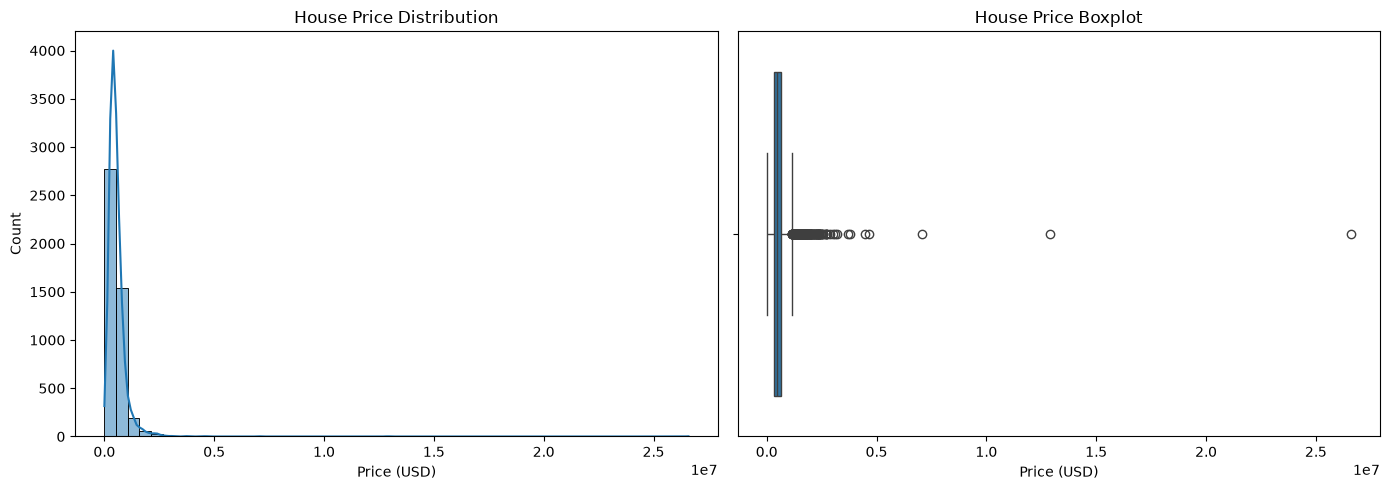

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_clean["price"], bins=50, kde=True, ax=axes[0])
axes[0].set_title("House Price Distribution")
axes[0].set_xlabel("Price (USD)")

sns.boxplot(x=df_clean["price"], ax=axes[1])
axes[1].set_title("House Price Boxplot")
axes[1].set_xlabel("Price (USD)")

plt.tight_layout()
plt.savefig("../outputs/graphs/house_price_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

### House Prices by Number of Bedrooms

This analysis compares house prices across different bedroom counts using a boxplot. It helps reveal differences in price distributions, typical price ranges, and potential outliers for properties with different numbers of bedrooms.

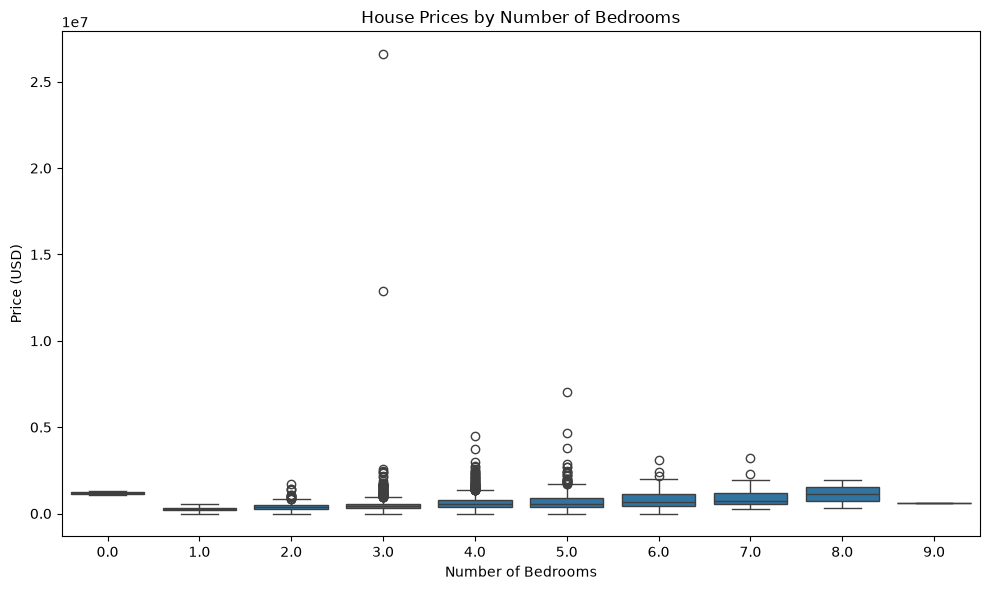

In [16]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df_clean, x="bedrooms", y="price")

plt.title("House Prices by Number of Bedrooms")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Price (USD)")
plt.tight_layout()
plt.savefig("../outputs/graphs/house_prices_by_bedrooms.png", dpi=300, bbox_inches="tight")
plt.show()

### Relationship Between Living Area and House Price

This analysis uses a scatter plot to examine the relationship between living area and house price. It helps identify trends, variation in prices for similarly sized properties, and potential outliers. The findings may also help determine whether living area is a useful feature for regression models.

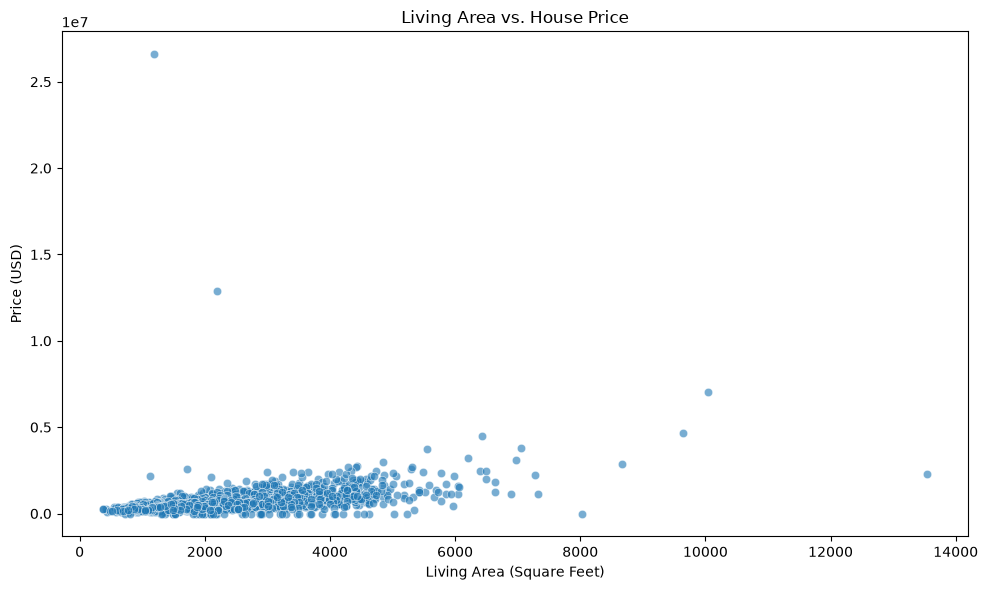

In [17]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="sqft_living",
    y="price",
    alpha=0.6
)

plt.title("Living Area vs. House Price")
plt.xlabel("Living Area (Square Feet)")
plt.ylabel("Price (USD)")
plt.tight_layout()
plt.savefig("../outputs/graphs/living_area_vs_price.png", dpi=300, bbox_inches="tight")
plt.show()

### Correlation Analysis

A correlation heatmap is used to examine the strength and direction of linear relationships between numerical features. This analysis helps identify features associated with house prices and highly correlated predictors that may provide overlapping information.

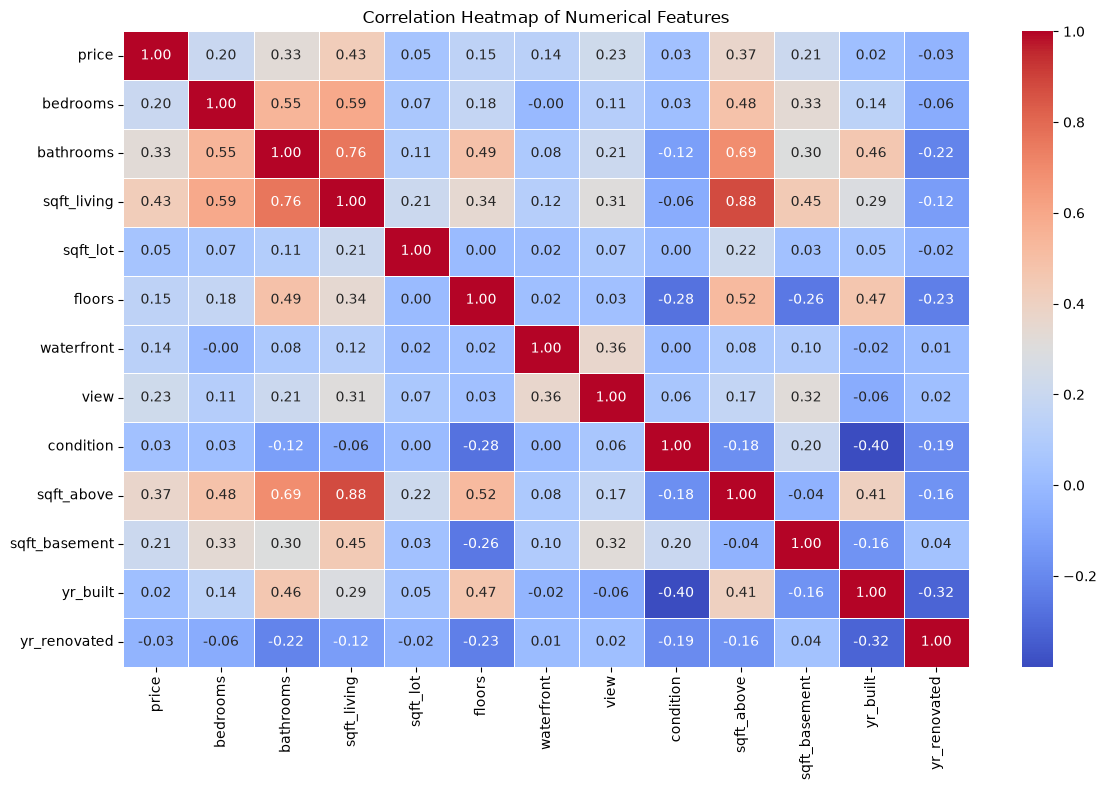

In [18]:
numerical_df = df_clean.select_dtypes(include="number")

plt.figure(figsize=(12, 8))

sns.heatmap(
    numerical_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.savefig("../outputs/graphs/correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

### Location-Wise House Price Analysis

This analysis compares median house prices across the ten cities with the highest number of property listings. Median prices are used to reduce the influence of unusually expensive properties. The visualization helps identify differences in typical property prices across locations.

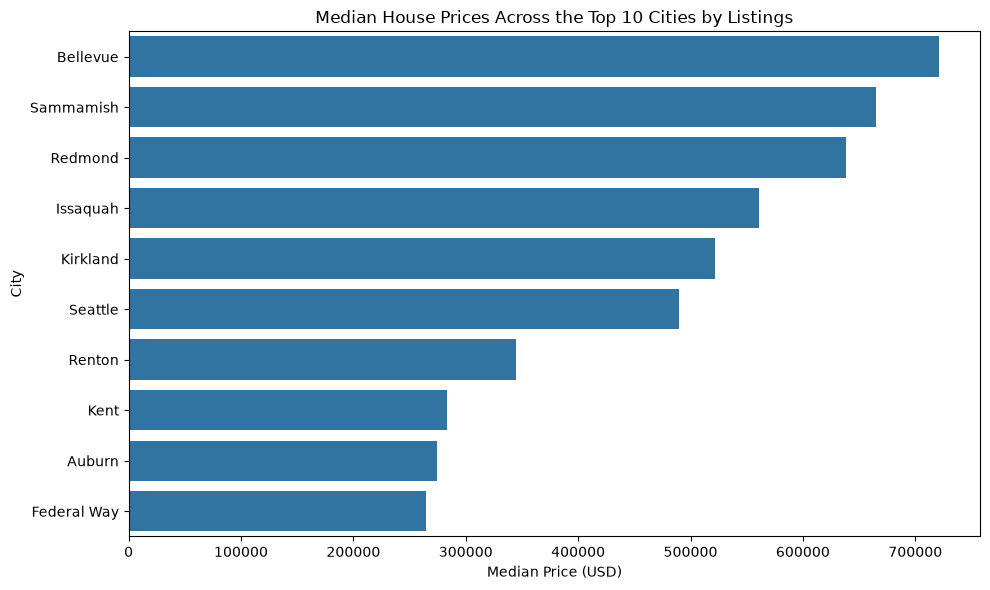

In [19]:
top_cities = df_clean["city"].value_counts().head(10).index

city_prices = (
    df_clean[df_clean["city"].isin(top_cities)]
    .groupby("city", as_index=False)["price"]
    .median()
    .sort_values("price", ascending=False)
)

plt.figure(figsize=(10, 6))

sns.barplot(data=city_prices, x="price", y="city")

plt.title("Median House Prices Across the Top 10 Cities by Listings")
plt.xlabel("Median Price (USD)")
plt.ylabel("City")
plt.tight_layout()
plt.savefig("../outputs/graphs/median_price_by_city.png", dpi=300, bbox_inches="tight")
plt.show()

### House Prices by Property Condition

This analysis compares house prices across different property condition ratings. A boxplot is used to examine the median, spread, and outliers in prices for each condition category. This helps investigate whether property condition is associated with house price in the dataset.

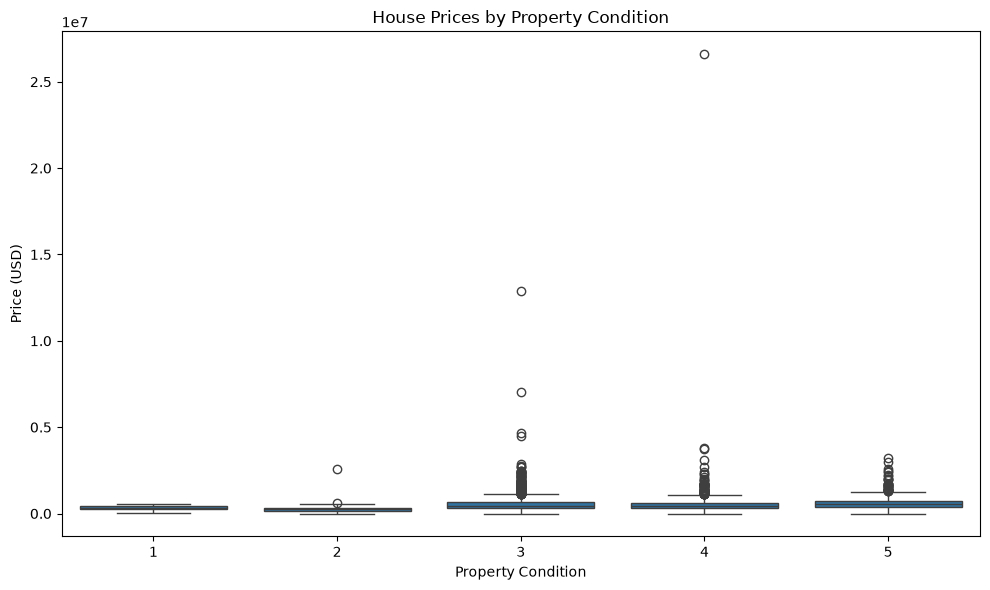

In [20]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df_clean, x="condition", y="price")

plt.title("House Prices by Property Condition")
plt.xlabel("Property Condition")
plt.ylabel("Price (USD)")
plt.tight_layout()
plt.savefig("../outputs/graphs/house_prices_by_condition.png", dpi=300, bbox_inches="tight")
plt.show()

### House Prices by Waterfront Status

This analysis compares the price distributions of properties based on waterfront status. A boxplot is used to examine differences in median prices, price variability, and outliers between waterfront and non-waterfront properties.

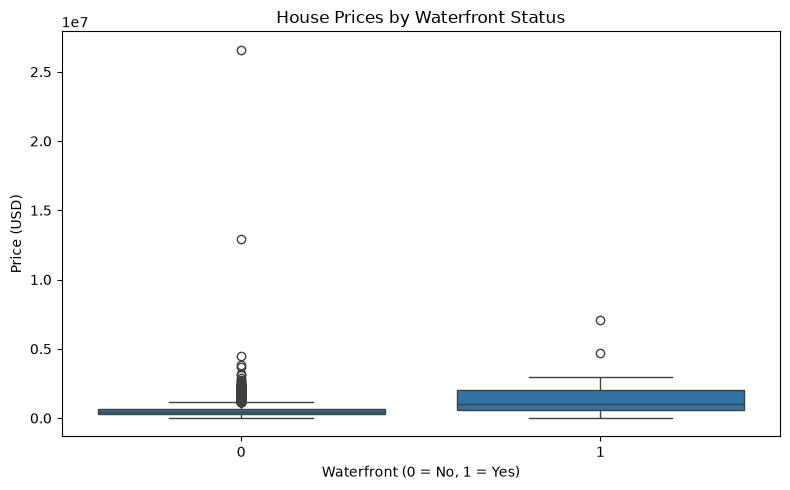

In [21]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df_clean, x="waterfront", y="price")

plt.title("House Prices by Waterfront Status")
plt.xlabel("Waterfront (0 = No, 1 = Yes)")
plt.ylabel("Price (USD)")
plt.tight_layout()
plt.savefig("../outputs/graphs/house_prices_by_waterfront.png", dpi=300, bbox_inches="tight")
plt.show()

### House Prices by Construction Period

This analysis examines how house prices vary across construction periods. The year built is grouped by decade, and the median price is calculated for each group. This helps reveal broad historical pricing patterns while reducing the complexity of comparing individual construction years.

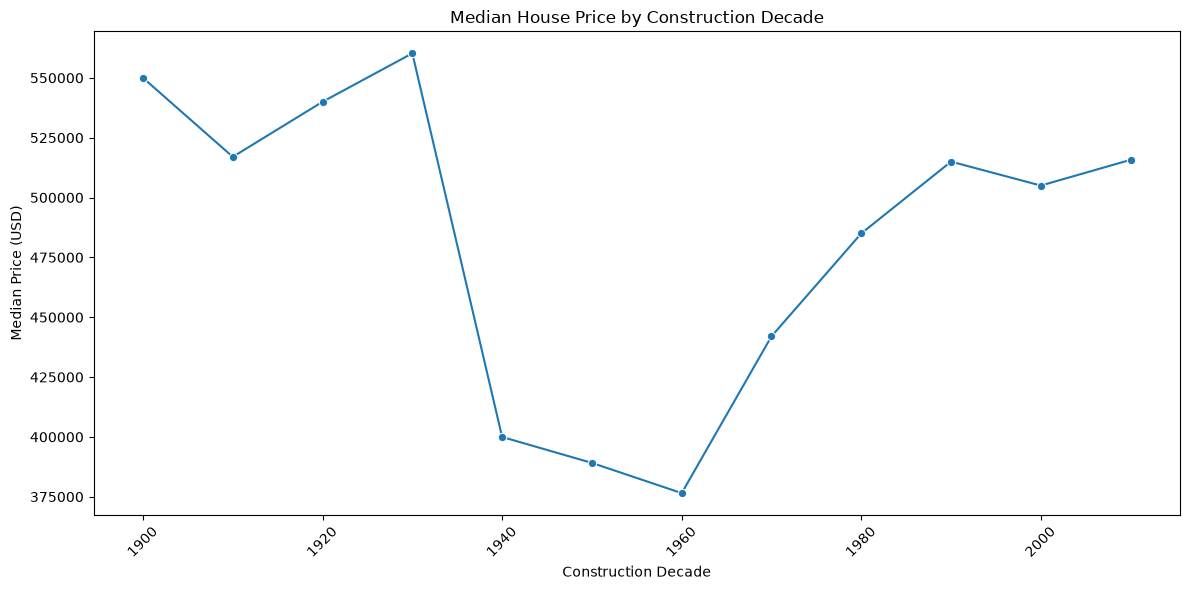

In [22]:
# Group construction years into decades
df_clean["built_decade"] = (df_clean["yr_built"] // 10) * 10

decade_prices = (
    df_clean.groupby("built_decade", as_index=False)["price"]
    .median()
)

plt.figure(figsize=(12, 6))

sns.lineplot(data=decade_prices, x="built_decade", y="price", marker="o")

plt.title("Median House Price by Construction Decade")
plt.xlabel("Construction Decade")
plt.ylabel("Median Price (USD)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../outputs/graphs/median_price_by_construction_decade.png", dpi=300, bbox_inches="tight")
plt.show()

### House Prices by Number of Floors

This analysis compares house price distributions across properties with different numbers of floors. A boxplot helps visualize differences in median prices, variability, and potential outliers among the floor categories.

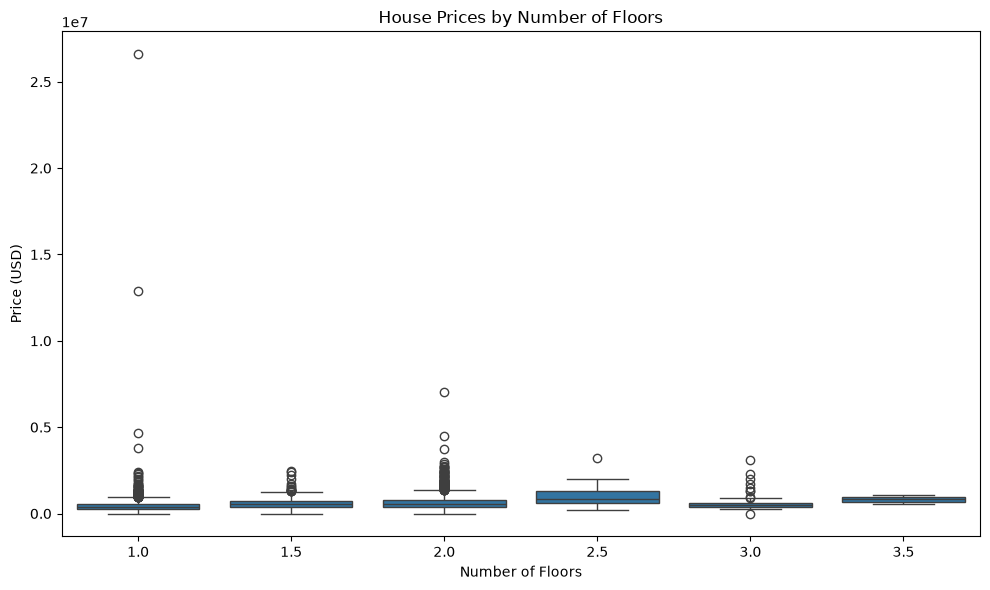

In [23]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df_clean, x="floors", y="price")

plt.title("House Prices by Number of Floors")
plt.xlabel("Number of Floors")
plt.ylabel("Price (USD)")
plt.tight_layout()
plt.savefig("../outputs/graphs/house_prices_by_floors.png", dpi=300, bbox_inches="tight")
plt.show()

### House Prices by Renovation Status

This analysis compares house prices based on whether a property has a recorded renovation year. In this dataset, a value of zero in `yr_renovated` indicates no recorded renovation year, while a nonzero value indicates a recorded year. A boxplot is used to compare the price distributions of these groups.

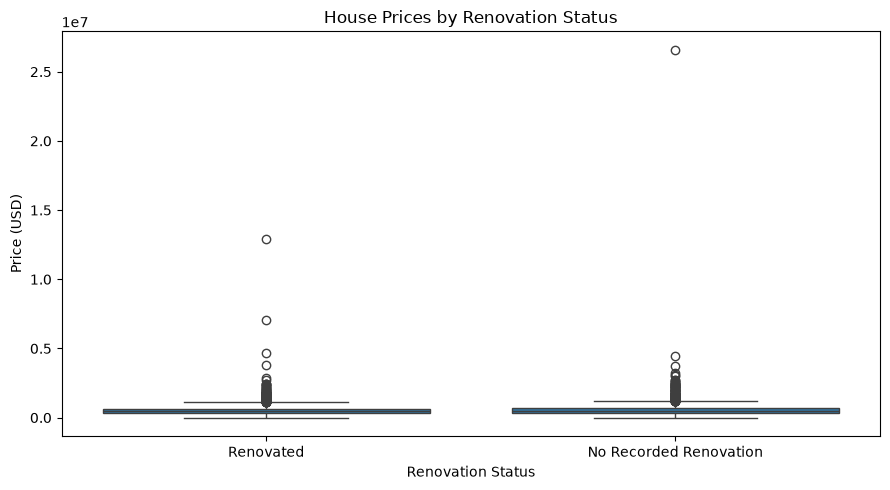

In [24]:
df_clean["renovation_status"] = np.where(
    df_clean["yr_renovated"] == 0,
    "No Recorded Renovation",
    "Renovated"
)

plt.figure(figsize=(9, 5))

sns.boxplot(data=df_clean, x="renovation_status", y="price")

plt.title("House Prices by Renovation Status")
plt.xlabel("Renovation Status")
plt.ylabel("Price (USD)")
plt.tight_layout()
plt.savefig("../outputs/graphs/house_prices_by_renovation_status.png", dpi=300, bbox_inches="tight")
plt.show()

### Exploratory Data Analysis Summary

The exploratory data analysis examined the distribution of house prices and relationships between prices and selected property characteristics.

Key observations:

- **House price distribution:** The histogram and boxplot helped examine price concentration, skewness, and potential outliers.
- **Living area:** `sqft_living` showed the strongest positive correlation with price among the numerical features, with a correlation coefficient of approximately 0.43.
- **Location:** Median house prices varied across cities. Bellevue had the highest median price, while Federal Way had the lowest among the ten cities analyzed.
- **Property characteristics:** Bedroom count, condition, waterfront status, number of floors, construction decade, and renovation status were explored to investigate their relationships with price.

These observations provide an initial understanding of the dataset. Correlation and visual patterns do not establish causation, and all potential predictors will be evaluated further during preprocessing and model development.

## 4. Data Preprocessing and Feature Selection

In this stage, the dataset is prepared for machine learning. The target variable is `price`, while relevant property and location characteristics are selected as input features.

The raw date and street address are excluded from the initial model because they require additional feature engineering or may introduce excessive high-cardinality information. The engineered construction-decade and renovation-status columns are retained for analysis only at this stage; the original numerical construction and renovation features will be used instead to keep preprocessing straightforward.

In [25]:
# Define the target variable
y = df_clean["price"]

# Select input features
feature_columns = [
    "bedrooms",
    "bathrooms",
    "sqft_living",
    "sqft_lot",
    "floors",
    "waterfront",
    "view",
    "condition",
    "sqft_above",
    "sqft_basement",
    "yr_built",
    "yr_renovated",
    "city",
    "statezip"
]

X = df_clean[feature_columns]

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

display(X.head())


Feature matrix shape: (4600, 14)
Target vector shape: (4600,)


,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,city,statezip
0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,Shoreline,WA 98133
1,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,Seattle,WA 98119
2,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,Kent,WA 98042
3,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,Bellevue,WA 98008
4,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,Redmond,WA 98052


### Train-Test Split

The dataset is divided into training and testing subsets. The training data will be used to fit the regression models, while the testing data will provide an independent evaluation of their predictive performance.

A fixed random state is used to make the split reproducible.

In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (3680, 14)
Testing features: (920, 14)
Training target: (3680,)
Testing target: (920,)


### Feature Preprocessing

The dataset contains both numerical and categorical features. Numerical features will be standardized, while categorical features will be converted into numerical values using one-hot encoding.

A `ColumnTransformer` will apply the appropriate transformation to each feature type. The preprocessing steps will be incorporated into machine learning pipelines so that transformations are learned from the training data only and then applied consistently to the test data.

In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify numerical and categorical features
numerical_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

# Define preprocessing for each feature type
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated']
Categorical features: ['city', 'statezip']


## 5. Model Training and Evaluation

### Model 1: Linear Regression

Linear Regression is a supervised learning algorithm that models the relationship between input features and a continuous target variable. In this project, it will learn from property characteristics and location information to predict house prices.

This model serves as a baseline against which the performance of more complex regression algorithms will be compared.

In [28]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Create the Linear Regression pipeline
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Train the model
linear_model.fit(X_train, y_train)

# Predict house prices on the test set
y_pred_linear = linear_model.predict(X_test)

print("Linear Regression training completed.")
print("Sample predictions:", y_pred_linear[:5])

Linear Regression training completed.
Sample predictions: [ 459623.40843675  238151.31923077 1241248.60826323  428872.66918013
  171492.88810966]


### Linear Regression Evaluation

The Linear Regression model is evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the coefficient of determination (R²).

MAE measures the average absolute prediction error, RMSE penalizes larger errors more strongly, and R² indicates how much variation in house prices is explained by the model. These metrics establish a baseline for comparison with the other regression algorithms.

In [29]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculate evaluation metrics
mae_linear = mean_absolute_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))
r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression Results")
print(f"MAE:  ${mae_linear:,.2f}")
print(f"RMSE: ${rmse_linear:,.2f}")
print(f"R² Score: {r2_linear:.4f}")

Linear Regression Results
MAE:  $155,719.54
RMSE: $981,709.04
R² Score: 0.0550


### Model 2: Random Forest Regressor

Random Forest is an ensemble learning algorithm that combines predictions from multiple decision trees. It can capture nonlinear relationships and interactions between property features.

In this project, the Random Forest Regressor will be trained and evaluated to determine whether it improves house price predictions compared with the Linear Regression baseline.

In [30]:
from sklearn.ensemble import RandomForestRegressor

# Create the Random Forest pipeline
random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
random_forest_model.fit(X_train, y_train)

# Predict house prices
y_pred_rf = random_forest_model.predict(X_test)

print("Random Forest training completed.")
print("Sample predictions:", y_pred_rf[:5])

Random Forest training completed.
Sample predictions: [ 453421.36        335961.11       1108971.64        377126.8325
  252626.68619048]


### Random Forest Evaluation

The Random Forest Regressor is evaluated on the test dataset using MAE, RMSE, and R². Its performance will be compared with the Linear Regression baseline to assess whether modeling nonlinear relationships improves prediction accuracy.

In [31]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Results")
print(f"MAE:  ${mae_rf:,.2f}")
print(f"RMSE: ${rmse_rf:,.2f}")
print(f"R² Score: {r2_rf:.4f}")

Random Forest Results
MAE:  $157,106.56
RMSE: $985,688.12
R² Score: 0.0473


### Model 3: Gradient Boosting Regressor

Gradient Boosting is an ensemble learning algorithm that builds decision trees sequentially, with each new tree attempting to improve the predictions of the existing ensemble.

In this project, Gradient Boosting will be evaluated to determine whether it can capture useful patterns in the property data and outperform the previous regression models.

In [32]:
from sklearn.ensemble import GradientBoostingRegressor

# Create the Gradient Boosting pipeline
gradient_boosting_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

# Train the model
gradient_boosting_model.fit(X_train, y_train)

# Predict house prices
y_pred_gb = gradient_boosting_model.predict(X_test)

print("Gradient Boosting training completed.")
print("Sample predictions:", y_pred_gb[:5])

Gradient Boosting training completed.
Sample predictions: [ 434588.94732735  364983.83205817 1044503.03482123  415040.85056353
  277941.91821076]


### Gradient Boosting Evaluation

The Gradient Boosting Regressor is evaluated using MAE, RMSE, and R² on the test dataset. Its results will be compared with Linear Regression and Random Forest to identify which model performs best among the three initial candidates.

In [33]:
mae_gb = mean_absolute_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
r2_gb = r2_score(y_test, y_pred_gb)

print("Gradient Boosting Results")
print(f"MAE:  ${mae_gb:,.2f}")
print(f"RMSE: ${rmse_gb:,.2f}")
print(f"R² Score: {r2_gb:.4f}")

Gradient Boosting Results
MAE:  $156,359.75
RMSE: $980,124.81
R² Score: 0.0580


### Model Performance Comparison

The three regression models are compared using MAE, RMSE, and R² on the same test dataset. Lower MAE and RMSE indicate smaller prediction errors, while a higher R² indicates that the model explains more variation in house prices.

In [34]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [mae_linear, mae_rf, mae_gb],
    "RMSE": [rmse_linear, rmse_rf, rmse_gb],
    "R2 Score": [r2_linear, r2_rf, r2_gb]
})

results = results.sort_values(
    by=["R2 Score", "MAE"],
    ascending=[False, True]
).reset_index(drop=True)

display(results.round(4))

,Model,MAE,RMSE,R2 Score
0,Gradient Boosting,156359.7538,980124.8056,0.0580
1,Linear Regression,155719.5403,981709.0386,0.0550
2,Random Forest,157106.5646,985688.1229,0.0473


### Actual vs. Predicted Prices

An actual-versus-predicted scatter plot is used to assess how closely the model's predictions match the true house prices. The dashed diagonal represents perfect predictions. Points far from this line indicate larger prediction errors.

Gradient Boosting is used for this initial diagnostic because it achieved the highest R² score among the three models evaluated so far.

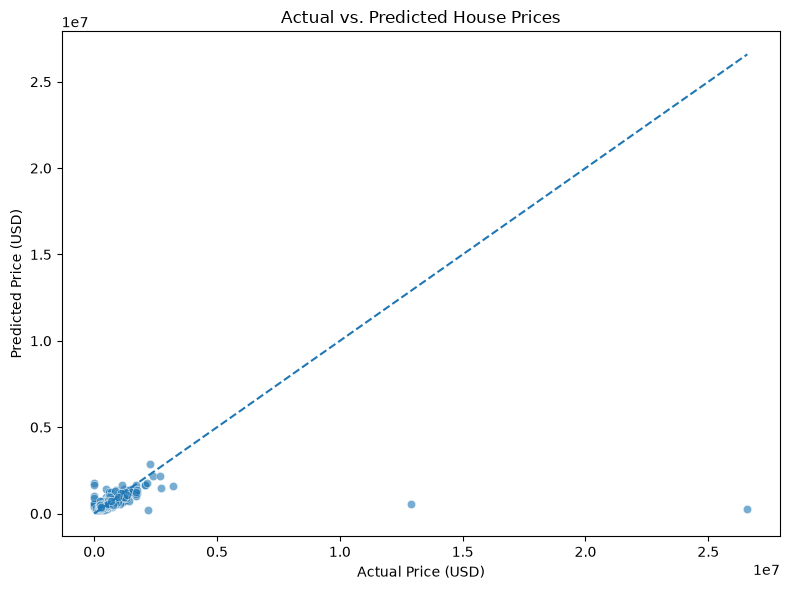

In [35]:
plt.figure(figsize=(8, 6))

sns.scatterplot(x=y_test, y=y_pred_gb, alpha=0.6)

# Reference line for perfect predictions
min_price = min(y_test.min(), y_pred_gb.min())
max_price = max(y_test.max(), y_pred_gb.max())
plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.title("Actual vs. Predicted House Prices")
plt.xlabel("Actual Price (USD)")
plt.ylabel("Predicted Price (USD)")
plt.tight_layout()
plt.savefig("../outputs/graphs/actual_vs_predicted_prices.png", dpi=300, bbox_inches="tight")
plt.show()

### Investigation of Extreme House Prices

Extreme target values can strongly affect regression metrics, particularly RMSE. In this step, the most expensive properties are inspected alongside their main characteristics to understand whether the dataset contains unusually high prices that require further investigation.

These records will not be removed automatically; any decision about outliers must be supported by the data.

In [36]:
df_clean.nlargest(
    10, "price"
)[[
    "price",
    "bedrooms",
    "bathrooms",
    "sqft_living",
    "sqft_lot",
    "waterfront",
    "condition",
    "city"
]]

,price,bedrooms,bathrooms,sqft_living,sqft_lot,waterfront,condition,city
4350,26590000.0,3.0,2.00,1180,7793,0,4,Kent
4346,12899000.0,3.0,2.50,2190,11394,0,3,Seattle
2286,7062500.0,5.0,4.50,10040,37325,1,3,Bellevue
2654,4668000.0,5.0,6.75,9640,13068,1,3,Mercer Island
2761,4489000.0,4.0,3.00,6430,27517,0,3,Bellevue
3729,3800000.0,5.0,5.50,7050,42840,0,4,Clyde Hill
1637,3710000.0,4.0,3.50,5550,28078,0,4,Medina
252,3200000.0,7.0,4.50,6210,8856,0,5,Seattle
1567,3100000.0,6.0,4.25,6980,15682,0,4,Mercer Island
2772,3000000.0,4.0,4.25,4850,12445,1,5,Kirkland


### House Price Distribution Analysis

The target variable is examined using descriptive statistics and percentile values. This helps identify unusual price values and assess whether the distribution is strongly skewed. The results will guide further preprocessing and model improvement decisions.

In [37]:
# Examine price distribution
display(df_clean["price"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
))

# Count zero and negative prices
print("Zero-priced properties:", (df_clean["price"] == 0).sum())
print("Negative-priced properties:", (df_clean["price"] < 0).sum())

# Calculate price skewness
print("Price skewness:", round(df_clean["price"].skew(), 3))

count    4.600000e+03
mean     5.519630e+05
std      5.638347e+05
min      0.000000e+00
1%       0.000000e+00
5%       2.000000e+05
25%      3.228750e+05
50%      4.609435e+05
75%      6.549625e+05
95%      1.184050e+06
99%      2.005220e+06
max      2.659000e+07
Name: price, dtype: float64

Zero-priced properties: 49
Negative-priced properties: 0
Price skewness: 24.791


### Log-Scale House Price Distribution

The house price distribution is visualized using a logarithmic horizontal axis to make both lower-priced and higher-priced properties easier to examine. This is a diagnostic visualization only; the original target values remain unchanged.

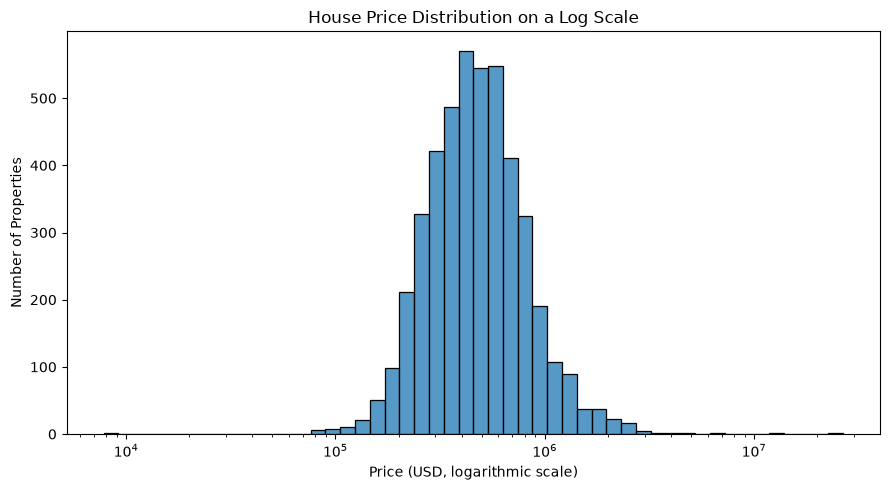

In [38]:
plt.figure(figsize=(9, 5))

sns.histplot(
    df_clean.loc[df_clean["price"] > 0, "price"],
    bins=50,
    log_scale=True,
    kde=False
)

plt.title("House Price Distribution on a Log Scale")
plt.xlabel("Price (USD, logarithmic scale)")
plt.ylabel("Number of Properties")
plt.tight_layout()
plt.savefig("../outputs/graphs/house_price_log_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

### Gradient Boosting with a Log-Transformed Target

A logarithmic transformation is applied to the training target to reduce the influence of large price values during model fitting. The model's predictions are converted back to the original price scale before calculating MAE, RMSE, and R². This experiment will determine whether target transformation improves predictive performance.

In [39]:
from sklearn.compose import TransformedTargetRegressor

log_gradient_boosting_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", TransformedTargetRegressor(
        regressor=GradientBoostingRegressor(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=3,
            random_state=42
        ),
        func=np.log1p,
        inverse_func=np.expm1
    ))
])

log_gradient_boosting_model.fit(X_train, y_train)

y_pred_gb_log = log_gradient_boosting_model.predict(X_test)

mae_gb_log = mean_absolute_error(y_test, y_pred_gb_log)
rmse_gb_log = np.sqrt(mean_squared_error(y_test, y_pred_gb_log))
r2_gb_log = r2_score(y_test, y_pred_gb_log)

print("Log-Transformed Gradient Boosting Results")
print(f"MAE:  ${mae_gb_log:,.2f}")
print(f"RMSE: ${rmse_gb_log:,.2f}")
print(f"R² Score: {r2_gb_log:.4f}")

Log-Transformed Gradient Boosting Results
MAE:  $197,334.10
RMSE: $1,000,866.68
R² Score: 0.0178


### Further Model Diagnostics

The initial regression models achieved low R² scores, and log-transforming the target did not improve performance. Further diagnostics are required to understand the limitations of the current models. This step examines the relationship between selected numerical features and house prices, along with the distribution of price values, before additional modeling decisions are made.

In [40]:
# Compare correlations with price
price_correlations = (
    df_clean.select_dtypes(include=np.number)
    .corr()["price"]
    .drop("price")
    .sort_values(key=abs, ascending=False)
)

display(price_correlations.to_frame("Correlation with Price"))

# Inspect the lowest and highest house prices
display(df_clean.nsmallest(10, "price")[["price", "sqft_living", "bedrooms", "city"]])
display(df_clean.nlargest(10, "price")[["price", "sqft_living", "bedrooms", "city"]])

,Correlation with Price
sqft_living,0.430410
sqft_above,0.367570
bathrooms,0.327110
view,0.228504
sqft_basement,0.210427
bedrooms,0.200336
floors,0.151461
waterfront,0.135648
sqft_lot,0.050451
condition,0.034915


,price,sqft_living,bedrooms,city
4354,0.0,1490,3.0,Federal Way
4356,0.0,2600,4.0,Seattle
4357,0.0,3200,6.0,Burien
4358,0.0,3480,5.0,Issaquah
4361,0.0,1500,5.0,Burien
4362,0.0,3680,4.0,Sammamish
4374,0.0,2200,2.0,Enumclaw
4376,0.0,2170,4.0,Normandy Park
4382,0.0,4630,5.0,Snoqualmie
4383,0.0,4430,5.0,Bellevue


,price,sqft_living,bedrooms,city
4350,26590000.0,1180,3.0,Kent
4346,12899000.0,2190,3.0,Seattle
2286,7062500.0,10040,5.0,Bellevue
2654,4668000.0,9640,5.0,Mercer Island
2761,4489000.0,6430,4.0,Bellevue
3729,3800000.0,7050,5.0,Clyde Hill
1637,3710000.0,5550,4.0,Medina
252,3200000.0,6210,7.0,Seattle
1567,3100000.0,6980,6.0,Mercer Island
2772,3000000.0,4850,4.0,Kirkland


### Target Variable Validation

The target variable is checked for invalid price values. Zero or negative prices may indicate data quality issues and can affect regression model training and evaluation. Any suspicious records will be investigated before deciding whether they should be excluded.

In [41]:
# Summarize the target variable
print("Minimum price:", df_clean["price"].min())
print("Maximum price:", df_clean["price"].max())
print("Zero prices:", (df_clean["price"] == 0).sum())
print("Negative prices:", (df_clean["price"] < 0).sum())

# Display records with non-positive prices
display(
    df_clean.loc[
        df_clean["price"] <= 0,
        ["price", "bedrooms", "bathrooms", "sqft_living", "city"]
    ]
)

Minimum price: 0.0
Maximum price: 26590000.0
Zero prices: 49
Negative prices: 0


,price,bedrooms,bathrooms,sqft_living,city
4354,0.0,3.0,1.75,1490,Federal Way
4356,0.0,4.0,2.75,2600,Seattle
4357,0.0,6.0,2.75,3200,Burien
4358,0.0,5.0,3.50,3480,Issaquah
4361,0.0,5.0,1.50,1500,Burien
4362,0.0,4.0,4.00,3680,Sammamish
4374,0.0,2.0,2.50,2200,Enumclaw
4376,0.0,4.0,2.25,2170,Normandy Park
4382,0.0,5.0,4.50,4630,Snoqualmie
4383,0.0,5.0,4.00,4430,Bellevue


### Baseline Model Evaluation

A baseline regressor that predicts the mean training price is evaluated on the test dataset. Its MAE, RMSE, and R² scores provide a reference point for assessing whether the trained regression models offer meaningful predictive improvement.

In [42]:
from sklearn.dummy import DummyRegressor

baseline_model = DummyRegressor(strategy="mean")
baseline_model.fit(X_train.select_dtypes(include=np.number), y_train)

# The baseline uses only numeric columns and predicts the training mean
y_pred_baseline = baseline_model.predict(
    X_test.select_dtypes(include=np.number)
)

mae_baseline = mean_absolute_error(y_test, y_pred_baseline)
rmse_baseline = np.sqrt(mean_squared_error(y_test, y_pred_baseline))
r2_baseline = r2_score(y_test, y_pred_baseline)

print("Mean Baseline Results")
print(f"MAE:  ${mae_baseline:,.2f}")
print(f"RMSE: ${rmse_baseline:,.2f}")
print(f"R² Score: {r2_baseline:.4f}")

Mean Baseline Results
MAE:  $277,797.29
RMSE: $1,010,500.78
R² Score: -0.0012


### Price Outlier Analysis

The Interquartile Range (IQR) method is used to identify unusually low or high house prices. These records will be examined to understand the extent of the price distribution. IQR flags indicate potential outliers, not necessarily invalid observations, so records will not be removed without further justification.

In [43]:
Q1 = df_clean["price"].quantile(0.25)
Q3 = df_clean["price"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df_clean[
    (df_clean["price"] < lower_bound) |
    (df_clean["price"] > upper_bound)
]

print(f"Lower IQR bound: ${lower_bound:,.2f}")
print(f"Upper IQR bound: ${upper_bound:,.2f}")
print(f"Potential price outliers: {len(outliers)}")
print(f"Percentage of dataset: {len(outliers) / len(df_clean) * 100:.2f}%")

display(
    outliers.nlargest(10, "price")[
        ["price", "bedrooms", "bathrooms", "sqft_living", "city"]
    ]
)

Lower IQR bound: $-175,256.25
Upper IQR bound: $1,153,093.75
Potential price outliers: 240
Percentage of dataset: 5.22%


,price,bedrooms,bathrooms,sqft_living,city
4350,26590000.0,3.0,2.00,1180,Kent
4346,12899000.0,3.0,2.50,2190,Seattle
2286,7062500.0,5.0,4.50,10040,Bellevue
2654,4668000.0,5.0,6.75,9640,Mercer Island
2761,4489000.0,4.0,3.00,6430,Bellevue
3729,3800000.0,5.0,5.50,7050,Clyde Hill
1637,3710000.0,4.0,3.50,5550,Medina
252,3200000.0,7.0,4.50,6210,Seattle
1567,3100000.0,6.0,4.25,6980,Mercer Island
2772,3000000.0,4.0,4.25,4850,Kirkland


### Outlier Sensitivity Experiment

Potential high-price outliers are excluded from the training data for an experimental comparison only. The test set remains unchanged so that performance is evaluated against the same real-world price distribution as the original model. This experiment does not imply that the flagged properties are invalid, and the original dataset is preserved.

In [44]:
# Keep training rows within the IQR upper bound
train_mask = y_train <= upper_bound

X_train_iqr = X_train.loc[train_mask]
y_train_iqr = y_train.loc[train_mask]

# Train Gradient Boosting on the filtered training data
gb_iqr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

gb_iqr_model.fit(X_train_iqr, y_train_iqr)

# Evaluate on the original, unchanged test set
y_pred_gb_iqr = gb_iqr_model.predict(X_test)

mae_gb_iqr = mean_absolute_error(y_test, y_pred_gb_iqr)
rmse_gb_iqr = np.sqrt(mean_squared_error(y_test, y_pred_gb_iqr))
r2_gb_iqr = r2_score(y_test, y_pred_gb_iqr)

print("Gradient Boosting — IQR Training Experiment")
print(f"Training rows retained: {len(y_train_iqr)} / {len(y_train)}")
print(f"MAE:  ${mae_gb_iqr:,.2f}")
print(f"RMSE: ${rmse_gb_iqr:,.2f}")
print(f"R² Score: {r2_gb_iqr:.4f}")

Gradient Boosting — IQR Training Experiment
Training rows retained: 3495 / 3680
MAE:  $172,041.18
RMSE: $992,915.93
R² Score: 0.0333


### Feature Engineering

Feature engineering creates additional predictors from existing data to help machine learning models identify useful patterns. In this step, house age at the time of sale and a renovation indicator are created from the construction year, renovation year, and sale date.

These features will be tested in a revised model rather than assumed to improve performance.

In [45]:
# Create a separate feature-engineering DataFrame
df_model = df_clean.copy()

# Calculate the year of sale
df_model["sale_year"] = df_model["date"].dt.year

# Calculate property age at the time of sale
df_model["house_age"] = (
    df_model["sale_year"] - df_model["yr_built"]
)

# Create a renovation indicator
df_model["was_renovated"] = (
    df_model["yr_renovated"] > 0
).astype(int)

# Display the new features
display(
    df_model[
        ["date", "yr_built", "sale_year", "house_age",
         "yr_renovated", "was_renovated", "price"]
    ].head()
)

,date,yr_built,sale_year,house_age,yr_renovated,was_renovated,price
0,2014-05-02,1955,2014,59,2005,1,313000.0
1,2014-05-02,1921,2014,93,0,0,2384000.0
2,2014-05-02,1966,2014,48,0,0,342000.0
3,2014-05-02,1963,2014,51,0,0,420000.0
4,2014-05-02,1976,2014,38,1992,1,550000.0


### Investigation of Zero-Priced Properties

The dataset is examined for properties with a recorded price of zero. Since house price is the target variable, these records require investigation before model training. Zero prices may represent missing or invalid values, but they will not be removed until their characteristics have been reviewed.

In [46]:
zero_price_houses = df_clean[df_clean["price"] == 0]

print("Number of zero-priced properties:", len(zero_price_houses))

display(
    zero_price_houses[
        [
            "price",
            "bedrooms",
            "bathrooms",
            "sqft_living",
            "sqft_lot",
            "condition",
            "city",
            "statezip"
        ]
    ].head(15)
)

Number of zero-priced properties: 49


,price,bedrooms,bathrooms,sqft_living,sqft_lot,condition,city,statezip
4354,0.0,3.0,1.75,1490,10125,4,Federal Way,WA 98001
4356,0.0,4.0,2.75,2600,5390,4,Seattle,WA 98199
4357,0.0,6.0,2.75,3200,9200,4,Burien,WA 98146
4358,0.0,5.0,3.50,3480,36615,4,Issaquah,WA 98075
4361,0.0,5.0,1.50,1500,7112,5,Burien,WA 98166
4362,0.0,4.0,4.00,3680,18804,3,Sammamish,WA 98074
4374,0.0,2.0,2.50,2200,188200,3,Enumclaw,WA 98022
4376,0.0,4.0,2.25,2170,10500,4,Normandy Park,WA 98166
4382,0.0,5.0,4.50,4630,6324,3,Snoqualmie,WA 98065
4383,0.0,5.0,4.00,4430,9000,3,Bellevue,WA 98004


### Remove Invalid Target Values

The dataset contains 49 properties with a recorded price of zero despite having realistic property characteristics. Since these records cannot provide meaningful sale-price targets, they are excluded from the modeling dataset.

The original `df_clean` dataset is preserved for reference. A separate dataset is created for model training and evaluation.

In [47]:

df_model = df_clean[df_clean["price"] > 0].copy()

print("Original dataset shape:", df_clean.shape)
print("Modeling dataset shape:", df_model.shape)
print("Remaining zero-priced properties:", (df_model["price"] == 0).sum())


Original dataset shape: (4600, 20)
Modeling dataset shape: (4551, 20)
Remaining zero-priced properties: 0



### Split the Cleaned Dataset

The cleaned dataset is divided into training and testing sets. The training set is used to fit the models, while the testing set evaluates how well they predict unseen house prices.

We use an 80:20 split and a fixed random state to make the experiment reproducible.


In [48]:

X = df_model[
    [
        "bedrooms", "bathrooms", "sqft_living", "sqft_lot",
        "floors", "waterfront", "view", "condition",
        "sqft_above", "sqft_basement", "yr_built",
        "yr_renovated", "city", "statezip"
    ]
]

y = df_model["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)


Training features shape: (3640, 14)
Testing features shape: (911, 14)
Training target shape: (3640,)
Testing target shape: (911,)


## 6. Model Training and Evaluation on cleaned data


### Train Linear Regression on Cleaned Data

Linear Regression is retrained using the cleaned dataset. We evaluate its predictions using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² score.


In [49]:

linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

linear_model.fit(X_train, y_train)

y_pred_linear = linear_model.predict(X_test)

mae_linear = mean_absolute_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))
r2_linear = r2_score(y_test, y_pred_linear)

print(f"Linear Regression MAE: ${mae_linear:,.2f}")
print(f"Linear Regression RMSE: ${rmse_linear:,.2f}")
print(f"Linear Regression R² Score: {r2_linear:.4f}")


Linear Regression MAE: $119,155.91
Linear Regression RMSE: $213,151.50
Linear Regression R² Score: 0.6946



### Train Random Forest on Cleaned Data

Random Forest combines predictions from multiple decision trees and can capture nonlinear relationships between property characteristics and prices.

We train it on the same training set and evaluate it on the same test set for a fair comparison with Linear Regression.


In [50]:

random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

y_pred_rf = random_forest_model.predict(X_test)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print(f"Random Forest MAE: ${mae_rf:,.2f}")
print(f"Random Forest RMSE: ${rmse_rf:,.2f}")
print(f"Random Forest R² Score: {r2_rf:.4f}")


Random Forest MAE: $128,081.23
Random Forest RMSE: $501,027.56
Random Forest R² Score: -0.6874



### Inspect Random Forest Prediction Errors

We compare actual and predicted prices and examine the largest absolute prediction errors. This helps identify whether a small number of extreme errors are affecting the model's performance.


In [51]:

rf_results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred_rf
})

rf_results["Absolute Error"] = (
    rf_results["Actual Price"] - rf_results["Predicted Price"]
).abs()

display(
    rf_results.sort_values(
        "Absolute Error", ascending=False
    ).head(10)
)



,Actual Price,Predicted Price,Absolute Error
895,250000.0,1.368635e+07,1.343635e+07
262,2280000.0,4.636423e+06,2.356423e+06
865,2199900.0,2.063964e+05,1.993504e+06
552,2110000.0,3.115230e+05,1.798477e+06
851,3800000.0,2.110582e+06,1.689418e+06
564,193000.0,1.797724e+06,1.604724e+06
41,535000.0,1.932665e+06,1.397665e+06
150,3200000.0,1.878858e+06,1.321142e+06
203,4668000.0,3.373141e+06,1.294859e+06
718,2700000.0,1.445269e+06,1.254731e+06



### Verify Random Forest Prediction Errors

We recalculate the absolute errors directly from the actual and predicted prices, then display the largest errors with consistent formatting. This ensures that the diagnostic results are reliable.


In [52]:

rf_results = pd.DataFrame({
    "Actual Price": np.asarray(y_test),
    "Predicted Price": y_pred_rf
})

rf_results["Absolute Error"] = (
    rf_results["Actual Price"] - rf_results["Predicted Price"]
).abs()

display(
    rf_results.nlargest(10, "Absolute Error").style.format({
        "Actual Price": "${:,.2f}",
        "Predicted Price": "${:,.2f}",
        "Absolute Error": "${:,.2f}"
    })
)



,Actual Price,Predicted Price,Absolute Error
895,"$250,000.00","$13,686,354.50","$13,436,354.50"
262,"$2,280,000.00","$4,636,422.90","$2,356,422.90"
865,"$2,199,900.00","$206,396.42","$1,993,503.58"
552,"$2,110,000.00","$311,523.00","$1,798,477.00"
851,"$3,800,000.00","$2,110,581.92","$1,689,418.08"
564,"$193,000.00","$1,797,724.08","$1,604,724.08"
41,"$535,000.00","$1,932,664.96","$1,397,664.96"
150,"$3,200,000.00","$1,878,858.00","$1,321,142.00"
203,"$4,668,000.00","$3,373,141.38","$1,294,858.62"
718,"$2,700,000.00","$1,445,268.72","$1,254,731.28"



### Investigate the Largest Random Forest Prediction Error

We inspect the property associated with the largest prediction error. Reviewing its characteristics may reveal unusual feature values, a rare property type, or a limitation in the model.


In [55]:

largest_error_position = rf_results["Absolute Error"].to_numpy().argmax()

print("Largest-error position:", largest_error_position)

display(
    X_test.iloc[[largest_error_position]]
)

display(
    rf_results.iloc[[largest_error_position]]
)


Largest-error position: 895


,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,city,statezip
3833,3.0,1.75,1200,24805,1.0,0,0,3,1200,0,1984,0,Kent,WA 98031


,Actual Price,Predicted Price,Absolute Error
895,250000.0,13686354.5,13436354.5



### Investigate Extreme Training Prices

We examine the highest-priced properties in the training data and compare their characteristics. This helps determine whether extreme prices or unusual property records may be contributing to the Random Forest prediction error.


In [56]:

display(
    df_model.nlargest(10, "price")[
        [
            "price", "bedrooms", "bathrooms", "sqft_living",
            "sqft_lot", "floors", "waterfront", "view",
            "city", "statezip"
        ]
    ]
)


,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,city,statezip
4350,26590000.0,3.0,2.00,1180,7793,1.0,0,0,Kent,WA 98031
4346,12899000.0,3.0,2.50,2190,11394,1.0,0,0,Seattle,WA 98199
2286,7062500.0,5.0,4.50,10040,37325,2.0,1,2,Bellevue,WA 98004
2654,4668000.0,5.0,6.75,9640,13068,1.0,1,4,Mercer Island,WA 98040
2761,4489000.0,4.0,3.00,6430,27517,2.0,0,0,Bellevue,WA 98004
3729,3800000.0,5.0,5.50,7050,42840,1.0,0,2,Clyde Hill,WA 98004
1637,3710000.0,4.0,3.50,5550,28078,2.0,0,2,Medina,WA 98039
252,3200000.0,7.0,4.50,6210,8856,2.5,0,2,Seattle,WA 98109
1567,3100000.0,6.0,4.25,6980,15682,3.0,0,4,Mercer Island,WA 98040
2772,3000000.0,4.0,4.25,4850,12445,2.0,1,4,Kirkland,WA 98034



### Investigate Extreme Price Records

We inspect the two most expensive properties in detail, including their living area, location, waterfront status, and other features. We will not remove these records unless there is evidence that their values are invalid.


In [57]:

extreme_price_houses = df_model.nlargest(2, "price")

display(
    extreme_price_houses[
        [
            "price", "bedrooms", "bathrooms", "sqft_living",
            "sqft_lot", "waterfront", "view", "condition",
            "yr_built", "yr_renovated", "city", "statezip"
        ]
    ].T
)


,4350,4346
price,26590000.0,12899000.0
bedrooms,3.0,3.0
bathrooms,2.0,2.5
sqft_living,1180,2190
sqft_lot,7793,11394
waterfront,0,0
view,0,0
condition,4,3
yr_built,1992,1956
yr_renovated,0,2001



### Train Gradient Boosting on Cleaned Data

Gradient Boosting builds decision trees sequentially, with each tree attempting to improve on the errors made by the previous trees.

We train it using the same cleaned training set and evaluate it on the same test set used for Linear Regression and Random Forest.


In [58]:

gradient_boosting_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

gradient_boosting_model.fit(X_train, y_train)

y_pred_gb = gradient_boosting_model.predict(X_test)

mae_gb = mean_absolute_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
r2_gb = r2_score(y_test, y_pred_gb)

print(f"Gradient Boosting MAE: ${mae_gb:,.2f}")
print(f"Gradient Boosting RMSE: ${rmse_gb:,.2f}")
print(f"Gradient Boosting R² Score: {r2_gb:.4f}")


Gradient Boosting MAE: $126,832.79
Gradient Boosting RMSE: $280,893.55
Gradient Boosting R² Score: 0.4696


## 7. Model Comparision and Saving


### Compare Model Performance

We compare Linear Regression, Random Forest, and Gradient Boosting using MAE, RMSE, and R² on the same test set.

Lower MAE and RMSE indicate smaller prediction errors, while a higher R² indicates that the model explains more variation in house prices.


In [59]:

model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [mae_linear, mae_rf, mae_gb],
    "RMSE": [rmse_linear, rmse_rf, rmse_gb],
    "R2 Score": [r2_linear, r2_rf, r2_gb]
})

display(
    model_comparison.sort_values("RMSE").style.format({
        "MAE": "${:,.2f}",
        "RMSE": "${:,.2f}",
        "R2 Score": "{:.4f}"
    })
)


,Model,MAE,RMSE,R2 Score
0,Linear Regression,"$119,155.91","$213,151.50",0.6946
2,Gradient Boosting,"$126,832.79","$280,893.55",0.4696
1,Random Forest,"$128,081.23","$501,027.56",-0.6874



### Save Model Comparison Results

The evaluation metrics for all three models are saved as a CSV file. This provides a record of model performance and supports the final model-selection decision.


In [60]:

model_comparison.to_csv(
    "../outputs/model_comparison.csv",
    index=False
)

print("Model comparison saved to outputs/model_comparison.csv")


Model comparison saved to outputs/model_comparison.csv



### Save the Best-Performing Model

Linear Regression achieved the lowest MAE and RMSE and the highest R² among the three evaluated models. We save the complete trained pipeline, including preprocessing and the regression model, so it can be reused without rebuilding the preprocessing steps.


In [61]:

import joblib

joblib.dump(
    linear_model,
    "../models/house_price_model.pkl"
)

print("Linear Regression model saved successfully.")


Linear Regression model saved successfully.



### Verify the Saved Model

We load the saved pipeline from disk and use it to predict the price of a property from the test set. This verifies that the saved model can be reused for future predictions.


In [62]:

loaded_model = joblib.load("../models/house_price_model.pkl")

sample_house = X_test.iloc[[0]]
actual_price = y_test.iloc[0]
predicted_price = loaded_model.predict(sample_house)[0]

print(f"Actual price: ${actual_price:,.2f}")
print(f"Predicted price: ${predicted_price:,.2f}")


Actual price: $1,225,000.00
Predicted price: $1,309,041.12



### Actual vs. Predicted House Prices

This scatter plot compares actual house prices with the prices predicted by Linear Regression. Points closer to the diagonal reference line represent more accurate predictions.


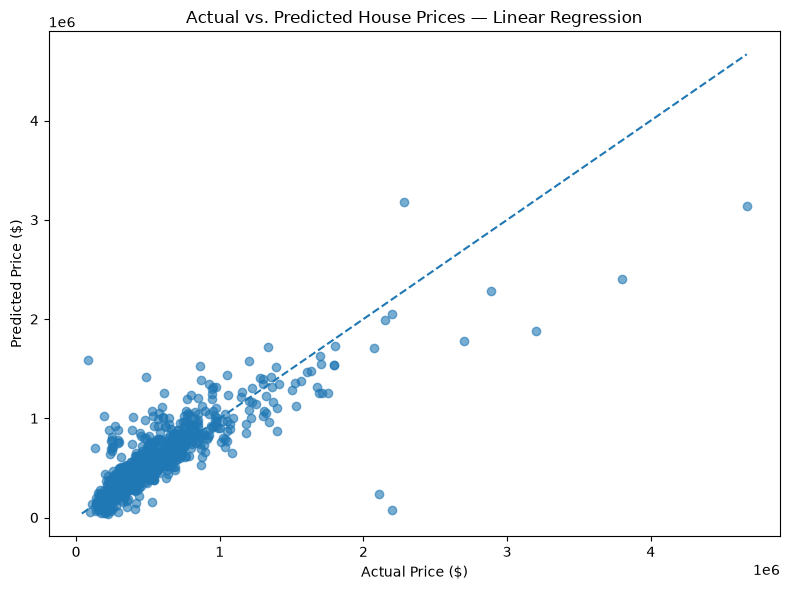

In [63]:

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_linear, alpha=0.6)

min_price = min(y_test.min(), y_pred_linear.min())
max_price = max(y_test.max(), y_pred_linear.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.title("Actual vs. Predicted House Prices — Linear Regression")
plt.tight_layout()

plt.savefig(
    "../outputs/graphs/actual_vs_predicted_prices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



## 8. Test the Saved Model on External Data

We create a small dataset containing new property records that were not used to train the model. The input columns must match the features and data types expected by the saved pipeline.


In [64]:

external_data = pd.DataFrame([
    {
        "bedrooms": 3,
        "bathrooms": 2.0,
        "sqft_living": 1500,
        "sqft_lot": 5000,
        "floors": 1.0,
        "waterfront": 0,
        "view": 0,
        "condition": 3,
        "sqft_above": 1500,
        "sqft_basement": 0,
        "yr_built": 2000,
        "yr_renovated": 0,
        "city": "Kent",
        "statezip": "WA 98031"
    },
    {
        "bedrooms": 4,
        "bathrooms": 3.0,
        "sqft_living": 2500,
        "sqft_lot": 7000,
        "floors": 2.0,
        "waterfront": 0,
        "view": 1,
        "condition": 4,
        "sqft_above": 2000,
        "sqft_basement": 500,
        "yr_built": 1995,
        "yr_renovated": 2010,
        "city": "Seattle",
        "statezip": "WA 98103"
    },
    {
        "bedrooms": 2,
        "bathrooms": 1.0,
        "sqft_living": 900,
        "sqft_lot": 4000,
        "floors": 1.0,
        "waterfront": 0,
        "view": 0,
        "condition": 3,
        "sqft_above": 900,
        "sqft_basement": 0,
        "yr_built": 1975,
        "yr_renovated": 0,
        "city": "Bellevue",
        "statezip": "WA 98004"
    }
])

display(external_data)


,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,city,statezip
0,3,2.0,1500,5000,1.0,0,0,3,1500,0,2000,0,Kent,WA 98031
1,4,3.0,2500,7000,2.0,0,1,4,2000,500,1995,2010,Seattle,WA 98103
2,2,1.0,900,4000,1.0,0,0,3,900,0,1975,0,Bellevue,WA 98004



### Predict Prices for External Properties

We load the saved Linear Regression pipeline and use it to predict prices for the external property records. The pipeline automatically applies the same preprocessing used during training.


In [65]:

import joblib

loaded_model = joblib.load("../models/house_price_model.pkl")

external_predictions = loaded_model.predict(external_data)

external_results = external_data.copy()
external_results["predicted_price"] = external_predictions

display(
    external_results[
        [
            "city", "bedrooms", "bathrooms", "sqft_living",
            "predicted_price"
        ]
    ].style.format({
        "predicted_price": "${:,.2f}"
    })
)


,city,bedrooms,bathrooms,sqft_living,predicted_price
0,Kent,3,2.000000,1500,"$758,005.44"
1,Seattle,4,3.000000,2500,"$820,412.74"
2,Bellevue,2,1.000000,900,"$901,499.74"



### Check Location Coverage in Training Data

The reliability of a prediction may depend on how well the training dataset represents its location. We count the training examples for each city and ZIP code used in our external test records.


In [66]:

for _, house in external_data.iterrows():
    city_count = (X_train["city"] == house["city"]).sum()
    zip_count = (X_train["statezip"] == house["statezip"]).sum()

    print(
        f'{house["city"]}, {house["statezip"]}: '
        f'{city_count} training records for city, '
        f'{zip_count} for ZIP code'
    )


Kent, WA 98031: 145 training records for city, 52 for ZIP code
Seattle, WA 98103: 1257 training records for city, 113 for ZIP code
Bellevue, WA 98004: 217 training records for city, 52 for ZIP code
